# RQ3 - Expert preference for the LLM reasoning (image vs text)

**Question:** Do experts prefer the LLM's reasoning when the input is an image (PNG) or text (SVG/XML)?

**Data:** `../llm-assesment-v2 - pairwise_preferences.csv`. Each row is a pairwise comparison where the expert picked `Response A`, `Response B`, or `Tie`; the chosen response's format is recorded in `Preferred_Format` (PNG / SVG / XML / Tie).

**Design:**
- Map `Preferred_Format`: `PNG -> image`, `SVG | XML -> text`, `Tie -> tie`.
- **Headline test (significance): chi-square goodness-of-fit** (df=1) comparing image vs text counts (ties excluded) against the null hypothesis of a 50/50 split.
- **Descriptive:** preference proportion with a **Wilson** 95% CI (interval estimate of the magnitude, not a test).
- **Breakdowns:** chi-square test of independence for `preference x Criterion` (main) and `preference x source model` (secondary).
- Tie rate reported separately.
- A light qualitative scaffold exports justifications grouped by preferred representation, plus a simple keyword tally (assistive, not full thematic coding)."

## 1. Load and code preferences

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import analysis_utils as au

NOTEBOOK_DIR = Path.cwd()
CSV_DIR = NOTEBOOK_DIR.parent
FIG_DIR = NOTEBOOK_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

PAIRWISE = CSV_DIR / "llm-assesment-v2 - pairwise_preferences.csv"
assert PAIRWISE.exists(), f"Missing {PAIRWISE}"


def code_preference(fmt: str) -> str:
    f = str(fmt).strip().lower()
    if f == "png":
        return "image"
    if f in ("svg", "xml"):
        return "text"
    if f == "tie":
        return "tie"
    return "unknown"


pw = pd.read_csv(PAIRWISE)
pw["Preference"] = pw["Preferred_Format"].apply(code_preference)

print(f"Total comparisons: {len(pw)}")
print("\nPreference coding (Preferred_Format -> Preference):")
print(pw.groupby(["Preferred_Format", "Preference"]).size().to_string())
print("\nOverall preference counts:")
print(pw["Preference"].value_counts().to_string())
assert (pw["Preference"] == "unknown").sum() == 0, "Unexpected Preferred_Format values"
pw[["Diagram_ID", "Criterion", "Guideline", "Internal_Source_Group", "Preferred_Format", "Preference"]].head()

Total comparisons: 253

Preference coding (Preferred_Format -> Preference):
Preferred_Format  Preference
PNG               image         113
SVG               text           41
Tie               tie            67
XML               text           32

Overall preference counts:
Preference
image    113
text      73
tie       67


,Diagram_ID,Criterion,Guideline,Internal_Source_Group,Preferred_Format,Preference
0,research-modifiability-pattern-experiment,accuracy,component_matching,ChatGPT,PNG,image
1,research-modifiability-pattern-experiment,clarity,element_identification,ChatGPT,XML,text
2,research-modifiability-pattern-experiment,completeness,coverage_main_components,ChatGPT,PNG,image
3,research-modifiability-pattern-experiment,consistency,notation_uniformity,ChatGPT,PNG,image
4,research-modifiability-pattern-experiment,level_of_detail,element_detail,ChatGPT,XML,text


## 2. Tie rate and overall proportions

In [2]:
n_total = len(pw)
n_image = int((pw["Preference"] == "image").sum())
n_text = int((pw["Preference"] == "text").sum())
n_tie = int((pw["Preference"] == "tie").sum())
n_decided = n_image + n_text

print(f"Total comparisons : {n_total}")
print(f"  image-preferred : {n_image}  ({n_image / n_total:.1%} of all)")
print(f"  text-preferred  : {n_text}  ({n_text / n_total:.1%} of all)")
print(f"  ties            : {n_tie}  ({n_tie / n_total:.1%} of all)")
print(f"\nDecided (non-tie) comparisons: {n_decided}")
print(f"  image share among decided: {n_image / n_decided:.1%}")
print(f"  text share among decided : {n_text / n_decided:.1%}")

Total comparisons : 253
  image-preferred : 113  (44.7% of all)
  text-preferred  : 73  (28.9% of all)
  ties            : 67  (26.5% of all)

Decided (non-tie) comparisons: 186
  image share among decided: 60.8%
  text share among decided : 39.2%


## 3. Headline significance test: chi-square goodness-of-fit (image vs text)

Null hypothesis H0: experts split 50/50 between image and text among decided comparisons (ties excluded). A significant result (p < 0.05) is evidence of a real preference for one representation.

In [3]:
gof = au.chi2_gof([n_image, n_text], expected_probs=[0.5, 0.5])

print("Chi-square goodness-of-fit (H0: image = text = 50/50, ties excluded)")
print(f"  observed: image={n_image}, text={n_text}")
print(f"  expected: image={gof.expected[0]:.1f}, text={gof.expected[1]:.1f}")
print("  " + gof.summary())

alpha = 0.05
if gof.p_value < alpha:
    winner = "image" if n_image > n_text else "text"
    print(f"\n=> Significant (p < {alpha}): experts prefer the {winner.upper()}-based reasoning.")
else:
    print(f"\n=> Not significant (p >= {alpha}): no robust preference between image and text.")

# Descriptive magnitude: Wilson 95% CI for the image share among decided comparisons.
p_img, lo_img, hi_img = au.wilson_ci(n_image, n_decided)
print(f"\nDescriptive (Wilson 95% CI) - image share among decided:")
print(f"  {p_img:.1%}  [{lo_img:.1%}, {hi_img:.1%}]")

Chi-square goodness-of-fit (H0: image = text = 50/50, ties excluded)
  observed: image=113, text=73
  expected: image=93.0, text=93.0
  chi2 = 8.6022, dof = 1, p = 0.003358, min expected = 93.00

=> Significant (p < 0.05): experts prefer the IMAGE-based reasoning.

Descriptive (Wilson 95% CI) - image share among decided:
  60.8%  [53.6%, 67.5%]


## 4. Breakdowns: chi-square test of independence

(a) `preference x Criterion` (main): does the image/text preference depend on the criterion? Ties excluded.

In [4]:
decided = pw[pw["Preference"].isin(["image", "text"])].copy()

crit_table = pd.crosstab(decided["Criterion"], decided["Preference"])
crit_table = crit_table.reindex(columns=["image", "text"], fill_value=0)
print("Contingency table (Criterion x Preference), ties excluded:")
display(crit_table)

res_crit = au.chi2_independence(crit_table.to_numpy())
print("Chi-square test of independence (preference x criterion):")
print("  " + res_crit.summary())
if res_crit.p_value < 0.05:
    print("  => Preference distribution differs across criteria.")
else:
    print("  => No evidence that preference depends on the criterion.")

# Per-criterion image share with Wilson CI (descriptive).
crit_rows = []
for crit, r in crit_table.iterrows():
    ni, nt = int(r["image"]), int(r["text"])
    nd = ni + nt
    p, lo, hi = au.wilson_ci(ni, nd) if nd else (np.nan, np.nan, np.nan)
    crit_rows.append({"Criterion": crit, "image": ni, "text": nt, "n_decided": nd,
                      "image_share": p, "ci_lo": lo, "ci_hi": hi})
crit_share = pd.DataFrame(crit_rows).set_index("Criterion")
crit_share.round(4)

Contingency table (Criterion x Preference), ties excluded:


Preference,image,text
Criterion,,
accuracy,18,15
clarity,29,18
completeness,23,11
consistency,28,13
level_of_detail,15,16


Chi-square test of independence (preference x criterion):
  chi2 = 4.1944, dof = 4, p = 0.3803, min expected = 12.17
  => No evidence that preference depends on the criterion.


,image,text,n_decided,image_share,ci_lo,ci_hi
Criterion,,,,,,
accuracy,18,15,33,0.5455,0.3799,0.7016
clarity,29,18,47,0.6170,0.4743,0.7421
completeness,23,11,34,0.6765,0.5084,0.8087
consistency,28,13,41,0.6829,0.5302,0.8044
level_of_detail,15,16,31,0.4839,0.3197,0.6516


(b) `preference x source model` (secondary): does preference depend on which model generated the compared pair (`Internal_Source_Group`)? Ties excluded.

In [5]:
model_table = pd.crosstab(decided["Internal_Source_Group"], decided["Preference"])
model_table = model_table.reindex(columns=["image", "text"], fill_value=0)
print("Contingency table (Source model x Preference), ties excluded:")
display(model_table)

res_model = au.chi2_independence(model_table.to_numpy())
print("Chi-square test of independence (preference x source model):")
print("  " + res_model.summary())
if res_model.p_value < 0.05:
    print("  => Preference distribution differs across source models.")
else:
    print("  => No evidence that preference depends on the source model.")

Contingency table (Source model x Preference), ties excluded:


Preference,image,text
Internal_Source_Group,,
ChatGPT,70,53
Claude,43,20


Chi-square test of independence (preference x source model):
  chi2 = 1.7977, dof = 1, p = 0.18, min expected = 24.73
  => No evidence that preference depends on the source model.


## 5. Charts

(a) Overall preference proportions (image / text / tie) — slim bars, no CI on figure.
(b) Normalized preference share by criterion (decided comparisons only).

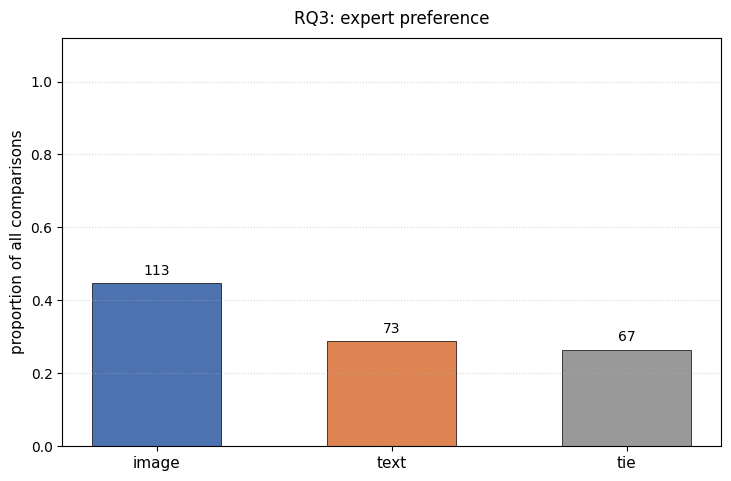

Saved figure: figures/rq3_overall_preference.png


In [6]:
labels = ["image", "text", "tie"]
counts = [n_image, n_text, n_tie]
props = [c / n_total for c in counts]
colors = [au.REP_COLORS["image"], au.REP_COLORS["text"], "#999999"]

fig, ax = plt.subplots(figsize=au.FIGSIZE)
au.slim_bar(
    ax,
    labels,
    props,
    colors,
    title="RQ3: expert preference",
    ylabel="proportion of all comparisons",
    ylim=(0, 1),
    show_counts=counts,
)
au.save_figure(fig, FIG_DIR / "rq3_overall_preference.png")
plt.show()
print("Saved figure: figures/rq3_overall_preference.png")

(b) 100% normalized stacked bar by criterion (decided comparisons: image% + text% = 100%).

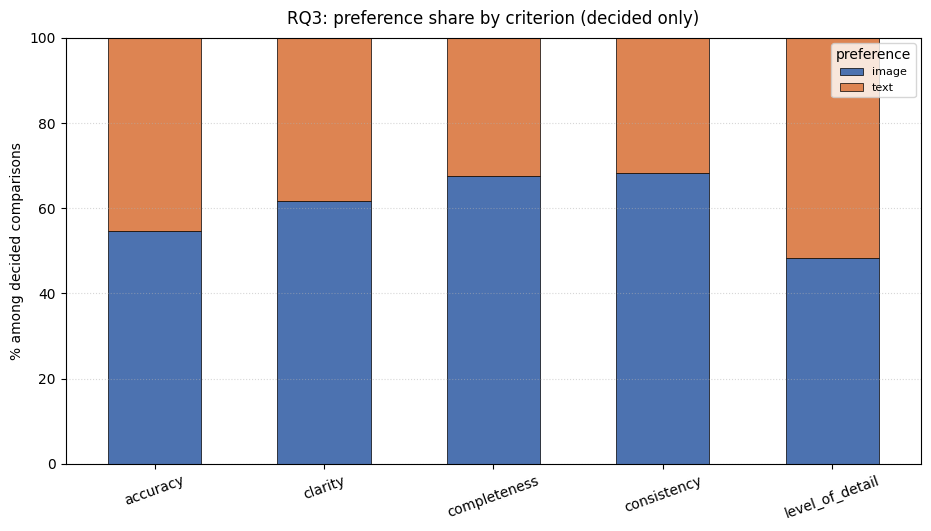

Saved figure: figures/rq3_preference_breakdowns.png


In [7]:
crit_pct = crit_table.div(crit_table.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=au.FIGSIZE_WIDE)
crit_pct.plot(
    kind="bar",
    stacked=True,
    ax=ax,
    color=[au.REP_COLORS["image"], au.REP_COLORS["text"]],
    edgecolor="black",
    linewidth=0.5,
    width=0.55,
)
ax.set_title("RQ3: preference share by criterion (decided only)", fontsize=12, pad=10)
ax.set_ylabel("% among decided comparisons")
ax.set_xlabel("")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=20)
ax.legend(title="preference", fontsize=8)
ax.grid(axis="y", linestyle=":", alpha=0.5)
au.save_figure(fig, FIG_DIR / "rq3_preference_breakdowns.png")
plt.show()
print("Saved figure: figures/rq3_preference_breakdowns.png")

## 7. Export summary

In [8]:
summary = pd.DataFrame(
    [
        {"metric": "n_total", "value": n_total},
        {"metric": "n_image", "value": n_image},
        {"metric": "n_text", "value": n_text},
        {"metric": "n_tie", "value": n_tie},
        {"metric": "image_share_decided", "value": round(p_img, 4)},
        {"metric": "image_share_ci_lo", "value": round(lo_img, 4)},
        {"metric": "image_share_ci_hi", "value": round(hi_img, 4)},
        {"metric": "gof_chi2", "value": round(gof.chi2, 4)},
        {"metric": "gof_p_value", "value": round(gof.p_value, 6)},
        {"metric": "indep_criterion_chi2", "value": round(res_crit.chi2, 4)},
        {"metric": "indep_criterion_p", "value": round(res_crit.p_value, 6)},
        {"metric": "indep_model_chi2", "value": round(res_model.chi2, 4)},
        {"metric": "indep_model_p", "value": round(res_model.p_value, 6)},
    ]
)
summary.to_csv(NOTEBOOK_DIR / "rq3_summary.csv", index=False)
crit_share.to_csv(NOTEBOOK_DIR / "rq3_preference_by_criterion.csv")
print("Saved: rq3_summary.csv, rq3_preference_by_criterion.csv, rq3_justifications.csv")
print("Saved figures in:", FIG_DIR)
summary

Saved: rq3_summary.csv, rq3_preference_by_criterion.csv, rq3_justifications.csv
Saved figures in: C:\Users\João Luiz\Desktop\Trabalhos facul\POC\llm-architecure-assesment\research-files\analysis-csv\rq-analysis\figures


,metric,value
0,n_total,253.000000
1,n_image,113.000000
2,n_text,73.000000
3,n_tie,67.000000
4,image_share_decided,0.607500
5,image_share_ci_lo,0.535900
6,image_share_ci_hi,0.674800
7,gof_chi2,8.602200
8,gof_p_value,0.003358
9,indep_criterion_chi2,4.194400
